# Agotados en Almacenes del Valle

Caso de Análisis de Datos 1. Una fila es una semana, una tienda y un SKU, entre el 6 de enero de 2025 y el 29 de junio de 2026.

**Los datos son sintéticos.** Tienen la estructura que produciría un ETL nocturno desde el punto de venta, el inventario y el calendario de promociones. No son un extracto de una empresa real. El archivo se genera con `src/generar_datos.py`.

**Pregunta.** ¿Qué factores operativos explican la tasa de agotado de 24 productos de alta rotación en las 12 tiendas, de modo que abastecimiento pueda bajarla de 28,3% a 18% o menos entre octubre de 2026 y marzo de 2027?

Este notebook hace tres cosas, en orden:

1. Deja la tabla analítica limpia y muestra el tamaño del problema.
2. Relaciona el agotado con cobertura, promoción, tienda y categoría.
3. Entrena una alerta para el lunes, sin usar información que ese día todavía no existe.


## 1. Carga y calidad

Se leen las 22.464 filas crudas. Antes de interpretar tasas se corrigen dos errores de captura que un ETL real también encontraría:

- Precio vacío: se imputa con la mediana del mismo SKU. Son pocos registros y el precio del SKU es estable.
- Inventario inflado (más de cuatro veces la demanda): se trata como un cero de más y se divide entre 10.

No se borran filas por estos errores. Borrarlas sesgaría las tiendas o productos donde el cajero se equivoca más.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# La carpeta del proyecto es esta, o la padre si el notebook se abre desde /notebook.
ROOT = Path.cwd()
for candidato in [ROOT, *ROOT.parents]:
    if (candidato / "datos" / "agotados_semanal.csv").exists():
        ROOT = candidato
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analizar import bivariate, cargar_y_limpiar, modelo, resumen_negocio

df, calidad = cargar_y_limpiar(ROOT / "datos" / "agotados_semanal.csv")

print("Filas crudas:      ", f"{calidad['filas_crudas']:,}")
print("Precios nulos:     ", calidad["precios_nulos"])
print("Inventarios raros: ", calidad["outliers_inventario"])
print("Duplicados:        ", calidad["duplicados"])
print("Filas limpias:     ", f"{calidad['filas_limpias']:,}")
print("Semanas:           ", df["semana"].nunique())
print("Tiendas x SKU:     ", df["tienda_id"].nunique(), "x", df["sku"].nunique())
print(df[["semana", "tienda", "producto", "en_promocion", "inventario_inicial",
          "demanda_estimada", "dias_agotado", "venta_perdida_cop"]].head(3).to_string(index=False))


Filas crudas:       22,464
Precios nulos:      89
Inventarios raros:  12
Duplicados:         0
Filas limpias:      22,464
Semanas:            78
Tiendas x SKU:      12 x 24
    semana      tienda         producto  en_promocion  inventario_inicial  demanda_estimada  dias_agotado  venta_perdida_cop
2025-01-06 Cali Centro Leche entera 1 L             0                2195              1891             0                  0
2025-01-13 Cali Centro Leche entera 1 L             0                1854              2062             1            1052099
2025-01-20 Cali Centro Leche entera 1 L             1                2275              3584             2            3873103


## 2. El tamaño del problema

La tasa de agotado es la fracción de filas con al menos un día sin inventario vendible. Es el KPI de la pregunta SMART.

La venta perdida es unidades faltantes por precio. Es una estimación: cuando el producto se agota, el POS no registra al cliente que se fue. Por eso el informe de ventas habitual subestima el problema.

`cobertura` es inventario inicial dividido por la demanda estimada de la misma semana. Sirve para describir. Más adelante no entra al modelo, porque el lunes esa demanda todavía no se conoce.


In [2]:
negocio = resumen_negocio(df)
semanas = negocio["semanas"]
print(f"Periodo: {negocio['desde']} a {negocio['hasta']} ({semanas} semanas)")
print(f"Tasa de agotado:        {negocio['tasa_agotado']:.1%}")
print(f"Tasa crítica (>=2 días): {negocio['tasa_critica']:.1%}")
print(f"Venta realizada:        {negocio['venta_cop']/1e6:,.0f} millones COP")
print(f"Venta perdida:          {negocio['venta_perdida_cop']/1e6:,.0f} millones COP")
print(f"Venta perdida al mes:   {negocio['venta_perdida_mensual_cop']/1e6:,.0f} millones COP")
print(f"Participación perdida:  {negocio['participacion_perdida']:.1%} de la venta potencial")
print(f"Con promoción:          {negocio['tasa_con_promo']:.1%}")
print(f"Sin promoción:          {negocio['tasa_sin_promo']:.1%}")
print(f"Semana con festivo:     {negocio['tasa_festivo']:.1%}")
print(f"Semana sin festivo:     {negocio['tasa_sin_festivo']:.1%}")

por_categoria = (
    df.groupby("categoria")
    .agg(tasa_agotado=("agotado", "mean"), venta_perdida_millones=("venta_perdida_cop", lambda s: s.sum() / 1e6))
    .sort_values("venta_perdida_millones", ascending=False)
)
por_tienda = (
    df.groupby("tienda")
    .agg(tasa_agotado=("agotado", "mean"), venta_perdida_millones=("venta_perdida_cop", lambda s: s.sum() / 1e6))
    .sort_values("tasa_agotado", ascending=False)
)
print("\nPor categoría")
print(por_categoria.round(3).to_string())
print("\nPor tienda")
print(por_tienda.round(3).to_string())


Periodo: 2025-01-06 a 2026-06-29 (78 semanas)
Tasa de agotado:        28.3%
Tasa crítica (>=2 días): 3.9%
Venta realizada:        87,531 millones COP
Venta perdida:          3,818 millones COP
Venta perdida al mes:   213 millones COP
Participación perdida:  4.2% de la venta potencial
Con promoción:          57.7%
Sin promoción:          23.1%
Semana con festivo:     35.1%
Semana sin festivo:     25.5%

Por categoría
           tasa_agotado  venta_perdida_millones
categoria                                      
Cárnicos          0.530                1375.535
Lácteos           0.502                1001.788
Bebidas           0.262                 641.623
Panadería         0.606                 386.257
Abarrotes         0.107                 301.191
Aseo              0.060                 111.250

Por tienda
                tasa_agotado  venta_perdida_millones
tienda                                              
Cali Centro            0.434                 720.289
Cali Norte             0.

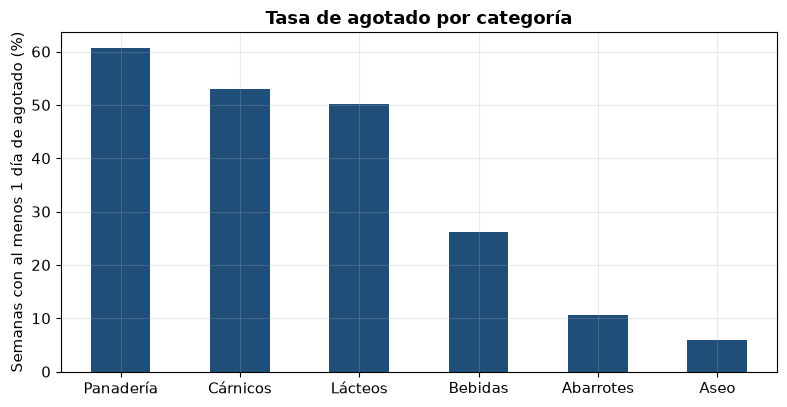

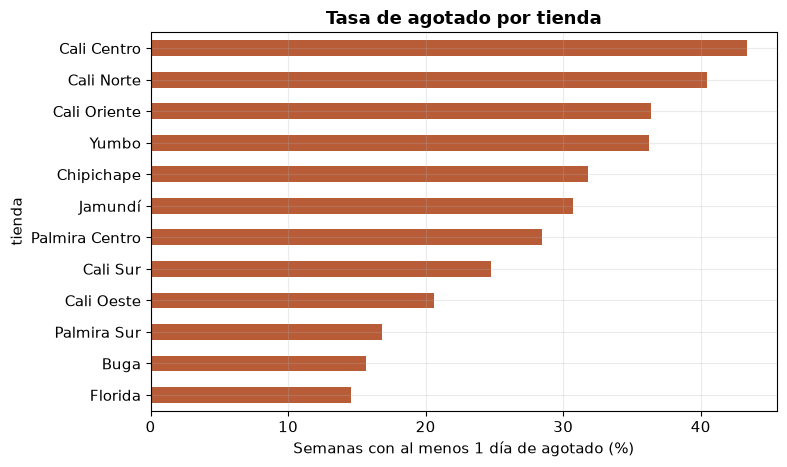

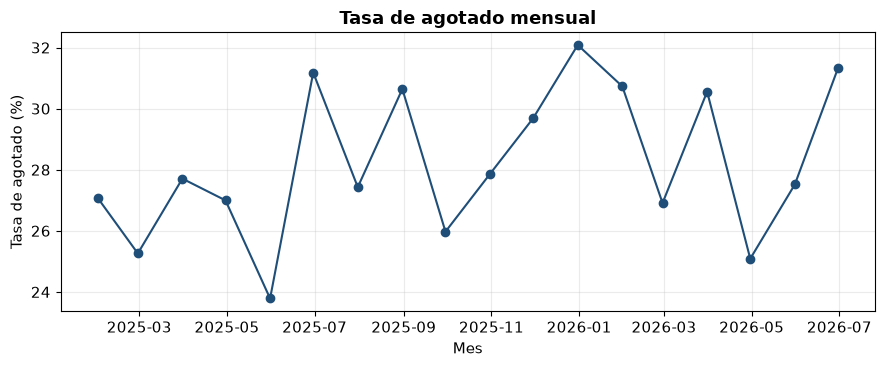

In [3]:
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 13, "font.size": 11})

fig, ax = plt.subplots(figsize=(8, 4.2))
tasas = por_categoria.sort_values("tasa_agotado", ascending=False)["tasa_agotado"] * 100
tasas.plot(kind="bar", color="#1f4e79", ax=ax)
ax.set_title("Tasa de agotado por categoría")
ax.set_ylabel("Semanas con al menos 1 día de agotado (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
tiendas = por_tienda.sort_values("tasa_agotado")["tasa_agotado"] * 100
tiendas.plot(kind="barh", color="#b85c38", ax=ax)
ax.set_title("Tasa de agotado por tienda")
ax.set_xlabel("Semanas con al menos 1 día de agotado (%)")
plt.tight_layout()
plt.show()

mensual = df.set_index("semana").resample("ME")["agotado"].mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(mensual.index, mensual.values, marker="o", color="#1f4e79")
ax.set_title("Tasa de agotado mensual")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()


### Cómo leer estas salidas

La tasa queda en 28,3% y la venta perdida en unos 213 millones de pesos al mes, el 4,2% de la venta potencial de estos productos. El agotado de dos días o más es solo 3,9%: la mayoría de quiebres dura un día, y aun así suman plata.

Panadería, cárnicos y lácteos superan el 50% de semanas con agotado. Aseo y abarrotes quedan por debajo del 11%. La venta perdida la lideran cárnicos y lácteos por precio y volumen, no solo por la tasa. Esas tres categorías frescas concentran cerca del 72% de los pesos perdidos.

Cali Centro está por encima del 43%. Florida y Buga quedan cerca del 15%. La serie mensual no tiene un único pico: se mueve entre 24% y 32%, con diciembre como mes más alto. El problema es estructural.

La promoción, vista sola, sube la tasa de 23,1% a 57,7%. El festivo la sube de 25,5% a 35,1%. Esas dos comparaciones son el puente al análisis de a dos variables.


## 3. Análisis bivariado

Aquí se mira el agotado contra una variable a la vez. La correlación de Pearson resume la dirección. Los gráficos muestran si la relación es pareja o si está concentrada en un extremo.

El descuento se reporta junto a la promoción para dejar explícito que no son dos hallazgos: el descuento solo existe cuando hay promo, así que las dos correlaciones salen parecidas.


In [4]:
bi = bivariate(df)
print("Correlaciones con días de agotado o venta perdida")
for nombre, valor in bi["correlaciones"].items():
    print(f"  {nombre:32s} {valor:+.2f}")

quintiles = pd.DataFrame(bi["por_quintil_cobertura"])
print("\nTasa de agotado por quintil de cobertura")
print(quintiles.assign(tasa_agotado=lambda t: (t["tasa_agotado"] * 100).round(1)).to_string(index=False))

promo = (
    df.groupby(["categoria", "en_promocion"])["agotado"].mean().unstack() * 100
)
promo = promo.rename(columns={0: "sin_promo", 1: "con_promo"})
print("\nTasa (%) con y sin promoción")
print(promo.round(1).to_string())


Correlaciones con días de agotado o venta perdida
  cobertura_vs_dias_agotado        -0.64
  promo_vs_dias_agotado            +0.34
  lead_time_vs_dias_agotado        -0.41
  festivo_vs_dias_agotado          +0.11
  retraso_vs_dias_agotado          +0.03
  descuento_vs_dias_agotado        +0.32
  cobertura_vs_venta_perdida       -0.48

Tasa de agotado por quintil de cobertura
    quintil  tasa_agotado  dias_promedio    n
Q1 más baja          96.0       1.169114 4494
         Q2          37.8       0.377783 4492
         Q3           3.9       0.039181 4492
         Q4           2.0       0.020476 4493
Q5 más alta           2.0       0.019586 4493

Tasa (%) con y sin promoción
en_promocion  sin_promo  con_promo
categoria                         
Abarrotes           5.1       36.8
Aseo                3.1       24.5
Bebidas            15.6       63.8
Cárnicos           47.5       96.8
Lácteos            43.1       95.5
Panadería          57.8       97.7


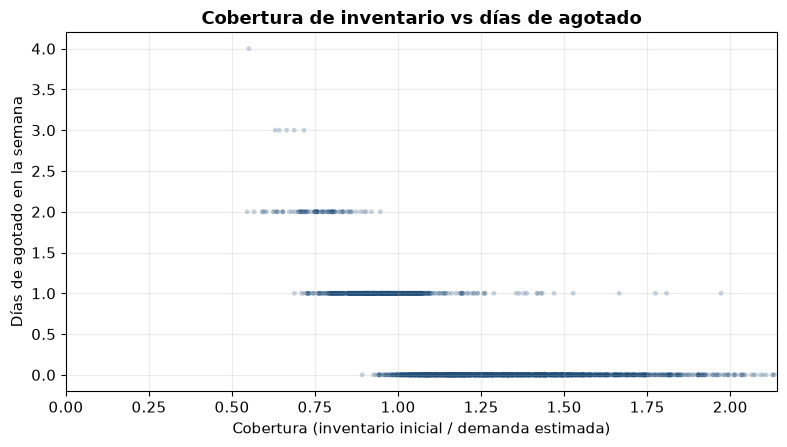

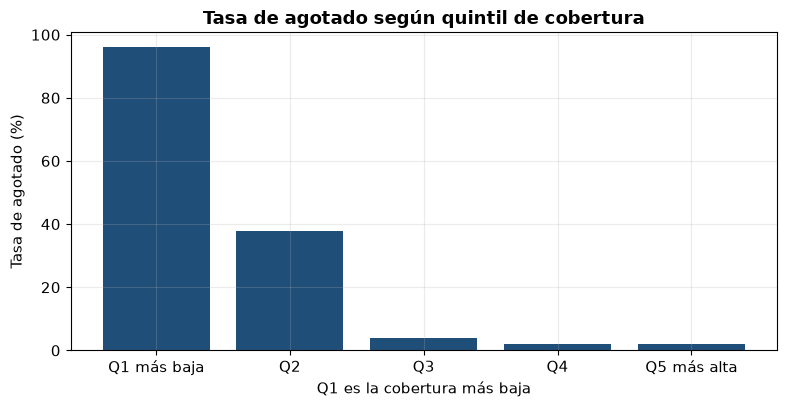

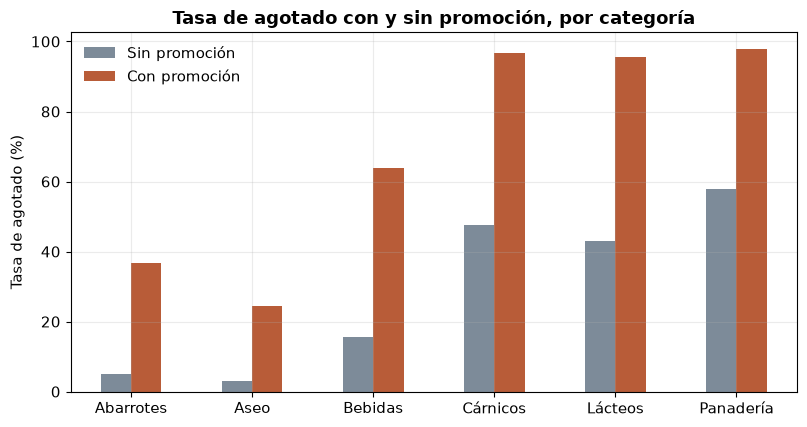

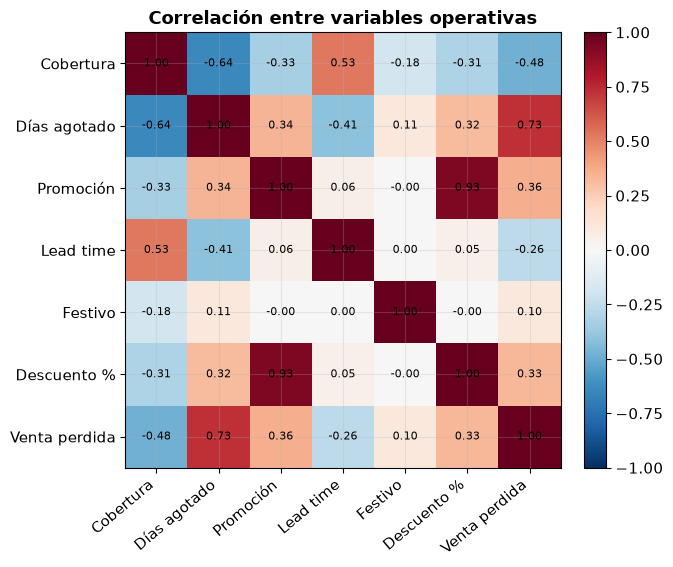

In [5]:
muestra = df.sample(n=2500, random_state=7)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(
    muestra["cobertura"],
    muestra["dias_agotado"],
    alpha=0.25,
    s=12,
    c="#1f4e79",
    edgecolors="none",
)
ax.set_xlim(0, muestra["cobertura"].quantile(0.995))
ax.set_title("Cobertura de inventario vs días de agotado")
ax.set_xlabel("Cobertura (inventario inicial / demanda estimada)")
ax.set_ylabel("Días de agotado en la semana")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(quintiles["quintil"], quintiles["tasa_agotado"] * 100, color="#1f4e79")
ax.set_title("Tasa de agotado según quintil de cobertura")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("Q1 es la cobertura más baja")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 4.4))
promo.plot(kind="bar", ax=ax, color=["#7d8b99", "#b85c38"])
ax.set_title("Tasa de agotado con y sin promoción, por categoría")
ax.set_ylabel("Tasa de agotado (%)")
ax.set_xlabel("")
ax.legend(["Sin promoción", "Con promoción"], frameon=False)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

columnas = ["cobertura", "dias_agotado", "en_promocion", "lead_time_dias", "festivo", "descuento_pct", "venta_perdida_cop"]
etiquetas = ["Cobertura", "Días agotado", "Promoción", "Lead time", "Festivo", "Descuento %", "Venta perdida"]
matriz = df[columnas].corr()
fig, ax = plt.subplots(figsize=(7.2, 5.8))
imagen = ax.imshow(matriz.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=40, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
for i in range(len(columnas)):
    for j in range(len(columnas)):
        ax.text(j, i, f"{matriz.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlación entre variables operativas")
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### Conclusiones del análisis bivariado

La cobertura es la relación fuerte: correlación de -0,64 con los días de agotado. En el quintil más bajo, el 96% de las semanas se agota. Del tercer quintil en adelante la tasa cae por debajo del 4%. El gráfico de dispersión muestra lo mismo sin esconder los casos sueltos de cobertura alta que igual fallan (inventario que el sistema reporta y la góndola no tiene).

La promoción correlaciona 0,34 con los días de agotado. El descuento correlaciona 0,32 y no se interpreta aparte: es la misma decisión comercial. En abarrotes la tasa pasa de cerca del 5% a cerca del 37% cuando hay promo. En lácteos, cárnicos y panadería, con promo el agotado queda por encima del 95%. Hay dos mecanismos: el fresco ya abre corto, y el seco se rompe cuando comercial empuja demanda y el pedido no sube.

El festivo correlaciona 0,11. Empeora la semana y no explica el nivel base.

El lead time correlaciona -0,41. No significa que un plazo largo proteja. Abarrotes y aseo tienen plazo largo y, a la vez, más colchón, porque no se vencen. El plazo está confundido con la categoría. El retraso puntual del proveedor correlaciona cerca de 0: en este corte no es la palanca.

Para la meta de 18%, las relaciones que sí indican acción son cobertura, promoción y la concentración en perecederos y en Cali Centro, Norte y Oriente.


## 4. Alerta del lunes

El modelo responde una pregunta distinta a la del gráfico de cobertura. El gráfico usa la demanda de la misma semana. El lunes, a la hora del pedido, esa demanda no existe.

Por eso el objetivo es `agotado` (sí o no en la semana que empieza) y las variables son solo las que ya están sobre la mesa:

- inventario inicial frente a la venta de la semana anterior;
- si la promoción de esa semana ya está publicada;
- categoría y ciudad;
- plazo pactado del proveedor, festivo ya conocido y mes;
- si la combinación tienda-SKU se agotó la semana pasada.

Quedan fuera la demanda estimada, las unidades faltantes, los días de agotado y la venta perdida de la misma semana. Meterlas sería fuga de información: el modelo vería el resultado disfrazado de causa.

El entrenamiento usa las semanas anteriores al 4 de mayo de 2026. La prueba son las nueve semanas siguientes, hasta el 29 de junio. No se mezclan semanas al azar, porque en la operación el futuro no se cuela en el pasado.

Se comparan tres cosas. Una regresión logística, que es el modelo elegido porque el coeficiente se puede explicar. Un bosque aleatorio, para ver si un modelo más flexible gana lo suficiente como para perder esa explicación. Y una regla simple: alertar toda promoción. Esa regla es el estándar de negocio contra el que hay que mejorar.

El umbral de la logística es 0,50. Se acepta una alerta de más, porque cuesta revisar un pedido, y se castiga dejar pasar un agotado, porque cuesta la venta. Por eso importa más el recall que una precisión perfecta.


In [6]:
resultado = modelo(df)
logistica = resultado["logistica"]
bosque = resultado["bosque"]
regla = resultado["regla_promocion"]

print("Objetivo:", resultado["objetivo"])
print("Entrenamiento:", resultado["corte_entrenamiento"], "filas", f"{resultado['filas_train']:,}")
print("Prueba:        ", resultado["corte_prueba"], "filas", f"{resultado['filas_test']:,}")
print("Variables:     ", ", ".join(resultado["variables"]))
print()

def mostrar(bloque):
    auc = "n/a" if bloque["auc"] is None else f"{bloque['auc']:.3f}"
    print(bloque["modelo"])
    print(f"  AUC {auc}   precisión {bloque['precision']:.1%}   recall {bloque['recall']:.1%}   exactitud {bloque['accuracy']:.1%}")
    print(f"  aciertos de agotado {bloque['tp']}   alertas falsas {bloque['fp']}   agotados no vistos {bloque['fn']}")

mostrar(logistica)
mostrar(bosque)
mostrar(regla)
print()
print(
    f"Venta perdida en la prueba: {resultado['venta_perdida_test_cop']/1e6:,.0f} millones. "
    f"El modelo señala {resultado['participacion_perdida_detectada']:.1%} de esa plata."
)
print("\nCoeficientes que más suben el riesgo (logística)")
for item in resultado["coef_suben_riesgo"]:
    print(f"  {item['variable']:32s} {item['coeficiente']:+.2f}")
print("Coeficientes que más lo bajan")
for item in resultado["coef_bajan_riesgo"]:
    print(f"  {item['variable']:32s} {item['coeficiente']:+.2f}")


Objetivo: agotado (al menos 1 día sin inventario vendible en la semana)
Entrenamiento: semanas anteriores al 2026-05-04 filas 19,584
Prueba:         2026-05-04 a 2026-06-29 filas 2,592
Variables:      cobertura_vs_semana_anterior, en_promocion, lead_time_dias, festivo, mes, agotado_semana_anterior, categoria, ciudad

Regresión logística
  AUC 0.853   precisión 54.9%   recall 82.3%   exactitud 74.7%
  aciertos de agotado 632   alertas falsas 519   agotados no vistos 136
Bosque aleatorio
  AUC 0.852   precisión 51.9%   recall 86.7%   exactitud 72.2%
  aciertos de agotado 666   alertas falsas 618   agotados no vistos 102
Regla: alertar toda promoción
  AUC n/a   precisión 58.7%   recall 31.8%   exactitud 73.1%
  aciertos de agotado 244   alertas falsas 172   agotados no vistos 524

Venta perdida en la prueba: 468 millones. El modelo señala 91.6% de esa plata.

Coeficientes que más suben el riesgo (logística)
  cat__ciudad_Yumbo                +0.66
  cat__categoria_Lácteos           +0.84

### Cómo leer el modelo, sin convertirlo en la decisión

En la prueba, cerca del 30% de las filas se agotan. La logística tiene AUC 0,85: ordena el riesgo bastante mejor que una moneda (0,50) y lejos de un ajuste perfecto (1). Avisa el 82% de los agotados. De las alertas, el 55% sí se agota. La exactitud, 75%, importa menos: con un evento frecuente, acertar los “no” es fácil.

El bosque aleatorio queda en el mismo AUC. No justifica reemplazar un coeficiente que abastecimiento puede discutir. La regla de “alertar toda promo” tiene una precisión parecida y un recall cercano al 32%: se le escapan los agotados de leche, carne y pan en semanas sin promoción, que son la mayoría de los pesos.

Los coeficientes van en la misma dirección que el análisis bivariado. Suben el riesgo panadería, cárnicos, lácteos y la promoción. Lo bajan aseo, abarrotes, Florida y Buga. El lead time puede pesar dentro del bosque porque distingue fresco de seco; no se presenta como causa. La causa que se comunica es la categoría.

En pesos, la lista del lunes habría marcado los casos donde estaba cerca del 92% de la venta perdida de esas nueve semanas. Eso no significa que el 92% se recupera solo. Se recupera si alguien alcanza a reponer o a frenar la promo.

### Supuestos y límites

- La demanda no observada se estima. Si la estimación está sesgada, la venta perdida también.
- El caso es sintético. Las relaciones están diseñadas para ser interpretables. Con el POS real van a ser más ruidosas y el AUC puede bajar.
- El modelo no arma la orden de compra. Prioriza una lista. El coordinador de abastecimiento sigue decidiendo.
- Una meta de 8% en seis meses no cabe en estos resultados. La meta de 18% sí cabe si se actúa sobre cobertura de perecederos en tres tiendas de Cali y sobre promociones sin pedido.

### Qué se haría con esto

El lunes el coordinador recibe la lista ordenada por venta en riesgo, no las  mil alertas por igual. La regla comercial que puede salir ya, sin esperar integración, es: estos 24 productos no entran en promo si el pedido extra no está confirmado.
